# Top-K Next Product Prediction
## 1. Project overview
Rank the K most likely next products after the current click, conditional on another click occurring in the same session. This is a ranking task implemented through multiclass classification.

- **RQ1:** Do ML models outperform Global Popularity and First-Order Markov?
- **RQ2:** Do context and history improve ranking beyond current product information?
- **RQ3:** How effectively is the actual next product ranked within Top-K?

**Primary metric: Hit Rate@5.** Select models and features by mean CV Hit Rate@5, with MRR@10 as the tie-breaker. Remaining feature ties favor fewer features. Report Hit Rate@1/3/10, Accuracy and Macro F1 as diagnostics.

The local CSV and `new_before_methodology_update.ipynb` are the data and code references; original files are not modified. This notebook changes the objective after an earlier Accuracy-oriented analysis. The same holdout has already been inspected: it is not a completely fresh confirmation dataset. All choices here use training CV, never test results.

## 2. Libraries and reproducibility

In [2]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
thread_limits = threadpool_limits(limits=2)
pd.set_option("display.max_columns", 15)
sns.set_theme(style="whitegrid")
display(pd.Series({"Python": platform.python_version(), "pandas": pd.__version__,
                   "numpy": np.__version__, "scikit-learn": sklearn.__version__}, name="Version").to_frame())

,Version
Python,3.13.14
pandas,2.3.1
numpy,2.3.1
scikit-learn,1.8.0


## 3. Load and validate clicks
Retain original row identifiers. Never remove rare products or intermediate clicks before creating the target. ORDER is the supplied click sequence; dates have day-level resolution.

In [3]:
df = pd.read_csv("e-shop clothing 2008.csv")
df.index.name = "Row_ID"
df = df.rename(columns={
    "year": "YEAR", "month": "MONTH", "day": "DAY", "order": "ORDER",
    "country": "COUNTRY", "session ID": "SESSION_ID",
    "page 1 (main category)": "CATEGORY", "page 2 (clothing model)": "MODEL",
    "colour": "COLOUR", "location": "LOCATION", "model photography": "PHOTOGRAPHY",
    "price": "PRICE", "price 2": "PRICE_2", "page": "PAGE"
})
print("Raw shape:", df.shape)
display(df.head())
display(df.isna().sum().rename("Missing").to_frame().T)
print("Duplicate rows:", df.duplicated().sum())
assert not df.isna().any().any() and not df.duplicated().any()
assert df.index.is_unique

print("Number of unique models:", df["MODEL"].nunique())

Raw shape: (165474, 14)


,YEAR,MONTH,DAY,ORDER,COUNTRY,SESSION_ID,CATEGORY,MODEL,COLOUR,LOCATION,PHOTOGRAPHY,PRICE,PRICE_2,PAGE
Row_ID,,,,,,,,,,,,,,
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


,YEAR,MONTH,DAY,ORDER,COUNTRY,SESSION_ID,CATEGORY,MODEL,COLOUR,LOCATION,PHOTOGRAPHY,PRICE,PRICE_2,PAGE
Missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Duplicate rows: 0
Number of unique models: 217


In [4]:
session_months = df[["YEAR", "MONTH", "SESSION_ID"]].drop_duplicates()
print("IDs reused across months:", session_months["SESSION_ID"].duplicated().sum())
assert not session_months["SESSION_ID"].duplicated().any(), "Reused IDs require a composite key."
assert not df.duplicated(["SESSION_ID", "ORDER"]).any()
assert df.groupby("SESSION_ID")["COUNTRY"].nunique().eq(1).all()
df = df.sort_values(["SESSION_ID", "ORDER"], kind="stable").copy()
assert df["ORDER"].eq(df.groupby("SESSION_ID").cumcount() + 1).all()
click_dates = pd.to_datetime(df[["YEAR", "MONTH", "DAY"]])
assert not click_dates.groupby(df["SESSION_ID"]).diff().lt(pd.Timedelta(0)).any()
print("Validated sessions:", df["SESSION_ID"].nunique())
df["Next_MODEL"] = df.groupby("SESSION_ID", sort=False)["MODEL"].shift(-1)
print("Clicks before / after excluding final clicks:", len(df), df["Next_MODEL"].notna().sum())
assert df["Next_MODEL"].isna().sum() == df["SESSION_ID"].nunique()

IDs reused across months: 0
Validated sessions: 24026
Clicks before / after excluding final clicks: 165474 141448


IDs are not reused between months, so the original session boundaries are retained. ORDER and dates support the provided sequence but cannot independently verify within-day timing. Terminal clicks supply labels for preceding clicks, but have no target themselves.

## 4. Historical features
Only current and past clicks are used. Keep missing history; the average excludes the current price.

In [5]:
g = df.groupby("SESSION_ID", sort=False)
df["Previous_MODEL"] = g["MODEL"].shift(1)
df["Previous_2_MODEL"] = g["MODEL"].shift(2)
df["Price_Change"] = df["PRICE"] - g["PRICE"].shift(1)
df["Average_Previous_Price"] = (g["PRICE"].cumsum() - df["PRICE"]) / g.cumcount().replace(0, np.nan)
df_model = df.loc[df["Next_MODEL"].notna()].copy()
product_features = ["MODEL", "CATEGORY", "COLOUR", "PRICE", "PRICE_2"]
context_features = ["ORDER", "PAGE", "LOCATION", "PHOTOGRAPHY"]
product_history = ["Previous_MODEL", "Previous_2_MODEL"]
price_history = ["Price_Change", "Average_Previous_Price"]
all_features = product_features + context_features + product_history + price_history
categorical_features = ["MODEL", "CATEGORY", "COLOUR", "PRICE_2", "LOCATION", "PHOTOGRAPHY"] + product_history
numerical_features = [f for f in all_features if f not in categorical_features]
for col in categorical_features + ["MONTH", "COUNTRY"]:
    df_model[col] = df_model[col].astype("category")
assert df_model.loc[df_model["ORDER"].eq(1), product_history + price_history].isna().all().all()
assert df_model.loc[df_model["ORDER"].le(2), "Previous_2_MODEL"].isna().all()
assert {"SESSION_ID", "Next_MODEL", "Next_PRICE", "Next_CATEGORY", "Next_COLOUR", "MONTH", "COUNTRY"}.isdisjoint(all_features)
display(df_model[["SESSION_ID", "ORDER", "MODEL"] + product_history + price_history + ["Next_MODEL"]].head(8))

,SESSION_ID,ORDER,MODEL,Previous_MODEL,Previous_2_MODEL,Price_Change,Average_Previous_Price,Next_MODEL
Row_ID,,,,,,,,
0,1,1,A13,NaN,NaN,NaN,NaN,A16
1,1,2,A16,A13,NaN,5.0,28.000000,B4
2,1,3,B4,A16,A13,19.0,30.500000,B17
3,1,4,B17,B4,A16,-14.0,37.666667,B8
4,1,5,B8,B17,B4,14.0,37.750000,C56
5,1,6,C56,B8,B17,5.0,40.600000,C57
6,1,7,C57,C56,B8,-24.0,43.333333,P67
7,1,8,P67,C57,C56,5.0,41.857143,P82


| Group | Features |
| --- | --- |
| Current Product | MODEL, CATEGORY, COLOUR, PRICE, PRICE_2 |
| Browsing Context | ORDER, PAGE, LOCATION, PHOTOGRAPHY |
| Product History | Previous_MODEL, Previous_2_MODEL |
| Price History | Price_Change, Average_Previous_Price |

MONTH and COUNTRY remain optional, excluded from default experiments. Encode categorical IDs categorically; ORDER and PAGE retain ordinal meanings. Session identifiers and row indexes are not predictors.

## 5. Session-disjoint split and CV
Use 80/20 GroupShuffleSplit and five fixed GroupKFold partitions within train. Single-click sessions cannot contribute labeled examples. Test targets are not inspected during EDA or selection.

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df_model, groups=df_model["SESSION_ID"]))
train_df, test_df = df_model.iloc[train_idx].copy(), df_model.iloc[test_idx].copy()

assert set(train_df["SESSION_ID"]).isdisjoint(test_df["SESSION_ID"])
assert len(train_df) + len(test_df) == len(df_model)

X_train, y_train = train_df[all_features], train_df["Next_MODEL"]
groups_train = train_df["SESSION_ID"]
group_cv = GroupKFold(n_splits=5)
folds = list(group_cv.split(X_train, y_train, groups_train))
fold_checks = []
for fold, (tr, va) in enumerate(folds, 1):
    assert set(groups_train.iloc[tr]).isdisjoint(groups_train.iloc[va])
    fold_checks.append([fold, len(tr), len(va), len(set(y_train.iloc[va]) - set(y_train.iloc[tr]))])

assert np.array_equal(np.sort(np.concatenate([va for _, va in folds])), np.arange(len(train_df)))

display(pd.DataFrame({"Rows": [len(train_df), len(test_df)],
                      "Sessions": [train_df["SESSION_ID"].nunique(), test_df["SESSION_ID"].nunique()]}, index=["Train", "Test"]))
display(pd.DataFrame(fold_checks, columns=["Fold", "Training_rows", "Validation_rows", "Unseen_validation_targets"]))

,Rows,Sessions
Train,112491,15187
Test,28957,3797


,Fold,Training_rows,Validation_rows,Unseen_validation_targets
0,1,89992,22499,0
1,2,89993,22498,0
2,3,89993,22498,0
3,4,89993,22498,0
4,5,89993,22498,2


Sessions do not overlap across split boundaries. Validation targets absent from fitted training classes remain ranking misses. Every learned transformation or ranking distribution must be fitted on the appropriate training partition.

## 6. Training-only EDA
Temporary next attributes are descriptive outcomes, never features. Derive them from complete training sessions including terminal clicks and align by Row_ID.

In [7]:
# Training sessions, including final clicks
train_clicks = df[
    df["SESSION_ID"].isin(train_df["SESSION_ID"])
].copy()

# Next-click attributes
cols = ["MODEL", "CATEGORY", "COLOUR", "PRICE"]

next_info = train_clicks.groupby("SESSION_ID")[cols].shift(-1)

# EDA dataset
eda = train_df.copy()

eda["Next_CATEGORY"] = next_info.loc[eda.index, "CATEGORY"]
eda["Next_COLOUR"] = next_info.loc[eda.index, "COLOUR"]
eda["Next_PRICE"] = next_info.loc[eda.index, "PRICE"]

# Validation
assert next_info.loc[eda.index, "MODEL"].equals(eda["Next_MODEL"])
assert eda[["Next_CATEGORY", "Next_COLOUR", "Next_PRICE"]].notna().all().all()

### 6.1 Target distribution and popularity coverage
These values are **training coverage**, not out-of-sample Hit Rates.

Number of classes: 216
Classes with <20 clicks: 3
Classes with <50 clicks: 4
Coverage@1: 1.96%
Coverage@3: 4.98%
Coverage@5: 7.69%
Coverage@10: 14.06%


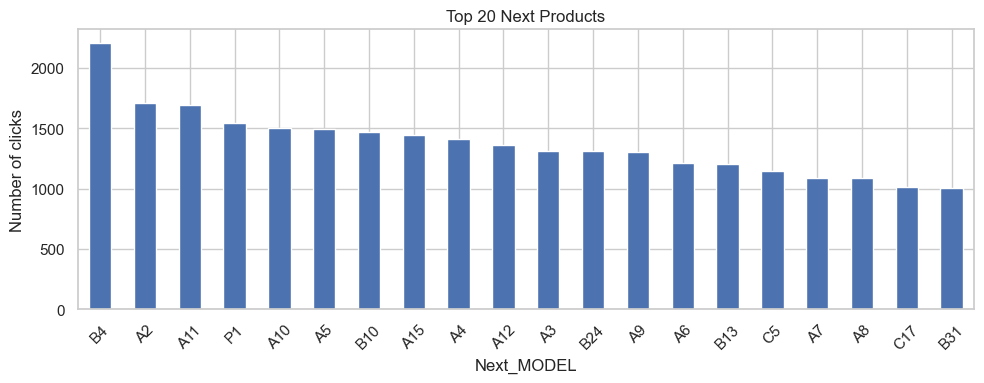

In [8]:
# Target distribution
target_counts = eda["Next_MODEL"].value_counts()

print("Number of classes:", len(target_counts))
print("Classes with <20 clicks:", (target_counts < 20).sum())
print("Classes with <50 clicks:", (target_counts < 50).sum())

# Popularity Coverage@K
popularity_coverage = {}

for k in [1, 3, 5, 10]:
    coverage = target_counts.head(k).sum() / len(eda)
    popularity_coverage[k] = coverage
    print(f"Coverage@{k}: {coverage:.2%}")

popularity_coverage = pd.Series(popularity_coverage)

# Top 20 most popular next products
plt.figure(figsize=(10, 4))
target_counts.head(20).plot(kind="bar")

plt.title("Top 20 Next Products")
plt.xlabel("Next_MODEL")
plt.ylabel("Number of clicks")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
all_models = set(df["MODEL"])
target_models = set(eda["Next_MODEL"])

missing_models = all_models - target_models

for model in missing_models:
    print("Missing MODEL:", model)
    print("Rows in original data:", (df["MODEL"] == model).sum())
    print("Rows in train:", (train_df["MODEL"] == model).sum())
    print("Rows in test:", (test_df["MODEL"] == model).sum())

Missing MODEL: P54
Rows in original data: 1
Rows in train: 0
Rows in test: 1


The dataset contains 217 unique products, but only 216 appear as target classes in the training set. Three target classes have fewer than 20 clicks, and four have fewer than 50 clicks, indicating that a small number of products have limited training observations.

The target distribution is highly dispersed, with the Top-5 most popular products covering only 7.69% of training clicks and the Top-10 covering 14.06%. This suggests that global popularity alone is insufficient for next-product prediction, motivating the use of context-dependent ranking models.

### 6.2 Current product and Markov coverage
Weight each transition row's Top-K probability mass by the current product's training frequency. Display only a small matrix slice; omitted targets remain in the denominator.

In [10]:
# Transition probabilities
transition_counts = pd.crosstab(eda["MODEL"], eda["Next_MODEL"])
transition_probs = transition_counts.div(
    transition_counts.sum(axis=1), axis=0
)

# Top 10 most frequent transitions
top_transitions = (
    eda.groupby(["MODEL", "Next_MODEL"], observed=True)
    .size()
    .nlargest(10)
    .reset_index(name="Transitions")
)
display(top_transitions)

# Same product rate
same_model = (eda["MODEL"] == eda["Next_MODEL"]).mean()
print(f"Same MODEL rate: {same_model:.2%}")

# Top 5 recommendations for 3 popular products
top_models = eda["MODEL"].value_counts().head(3).index

top5_table = pd.DataFrame({
    "Current_MODEL": top_models,
    "Top_5_next_products": [
        ", ".join(transition_probs.loc[model].nlargest(5).index)
        for model in top_models
    ]
})
display(top5_table)

# Markov Coverage@K
weights = transition_counts.sum(axis=1) / len(eda)
markov_coverage = {}

for k in [1, 3, 5, 10]:
    top_k_probs = transition_probs.apply(
        lambda row: row.nlargest(k).sum(), axis=1
    )
    markov_coverage[k] = (top_k_probs * weights).sum()

# Compare with Global Popularity
coverage_table = pd.DataFrame({
    "Popularity": popularity_coverage,
    "Markov": pd.Series(markov_coverage)
})

coverage_table.index.name = "K"
display(coverage_table.style.format("{:.2%}"))

,MODEL,Next_MODEL,Transitions
0,A1,A2,532
1,A2,A3,473
2,P1,P2,330
3,A5,A6,326
4,A7,A8,265
5,A9,A10,253
6,B10,B11,250
7,A3,A5,248
8,A8,A9,241
9,B10,B13,226


Same MODEL rate: 5.27%


,Current_MODEL,Top_5_next_products
0,B4,"B3, B4, B2, B10, B9"
1,A2,"A3, A5, A11, A2, A4"
2,A11,"A12, A10, A11, A13, A15"


,Popularity,Markov
K,,
1,1.96%,13.30%
3,4.98%,27.98%
5,7.69%,38.13%
10,14.06%,54.87%


### Interpretation

The transition analysis shows that some product pairs occur more frequently than others. For example, A1 → A2 is the most frequent transition (532 observations), followed by A2 → A3 (473 observations). However, the same-product rate is only 5.27%, suggesting that users usually click on a different product in their next interaction.

The Top-5 transition results show that the most likely next products vary depending on the current product. For example, A2 is most frequently followed by A3, A5, and A11, while A11 is most frequently followed by A12 and A10. This suggests that the current product can provide useful information for next-product recommendation.

The coverage comparison further shows that the Markov approach captures more next-product probability mass than Global Popularity at every evaluated K. At K = 5, Markov Coverage is 38.13%, compared with 7.69% for Global Popularity. At K = 10, the values increase to 54.87% and 14.06%, respectively. This indicates that accounting for the current product's transition patterns provides a more concentrated distribution of likely next products than using overall popularity alone.

**Note:** These coverage values describe patterns in the EDA data and are not out-of-sample recommendation performance. The actual predictive effectiveness of Markov and other models should be assessed using the same validation splits and Top-K evaluation metrics.

### 6.3 Previous products and sequential browsing
Compare Top-5 lists with and without previous-product conditioning. Display only history groups with at least 50 clicks; do not filter modeling observations.

In [11]:
# Top 3 most popular current products
top_models = eda["MODEL"].value_counts().head(3).index

history_rows = []

for model in top_models:
    subset = eda[eda["MODEL"] == model]

    # Top 5 next products, regardless of previous product
    top5 = subset["Next_MODEL"].value_counts().head(5).index
    history_rows.append([
        model, "All previous products", len(subset),
        ", ".join(top5)
    ])

    # Top 2 previous products with at least 50 observations
    previous_counts = subset["Previous_MODEL"].value_counts()
    previous_models = previous_counts[previous_counts >= 50].head(2).index

    for previous in previous_models:
        pair = subset[subset["Previous_MODEL"] == previous]
        top5 = pair["Next_MODEL"].value_counts().head(5).index

        history_rows.append([
            model, previous, len(pair), ", ".join(top5)
        ])

history_table = pd.DataFrame(
    history_rows,
    columns=[
        "Current_MODEL", "Previous_MODEL",
        "Count", "Top_5_next_products"
    ]
)

display(history_table)

,Current_MODEL,Previous_MODEL,Count,Top_5_next_products
0,B4,All previous products,2432,"B3, B4, B2, B10, B9"
1,B4,B3,144,"B5, B6, B9, B3, B2"
2,B4,B1,122,"B10, B9, B13, B17, B2"
3,A2,All previous products,2104,"A3, A5, A11, A2, A4"
4,A2,A1,513,"A3, A5, A4, A11, A2"
5,A2,A2,105,"A3, A2, A4, A5, A11"
6,A11,All previous products,1932,"A12, A10, A11, A15, A13"
7,A11,A10,214,"A12, A11, A13, A14, A5"
8,A11,A2,113,"A10, A5, A13, A11, A3"


**Interpretation:** The results suggest that the previous product is associated with differences in next-product patterns, even when the current product remains the same. For example, after viewing B4, the most frequent next products differ depending on whether the previous product was B3 or B1. Similar patterns are observed for A2 and A11. This suggests that browsing history may provide additional information for next-product recommendation. However, whether these history features improve predictive performance needs to be evaluated using Top-K metrics.

### 6.4 Category and candidate relevance

Same-category rate: 81.12%
Products with multiple categories: 1


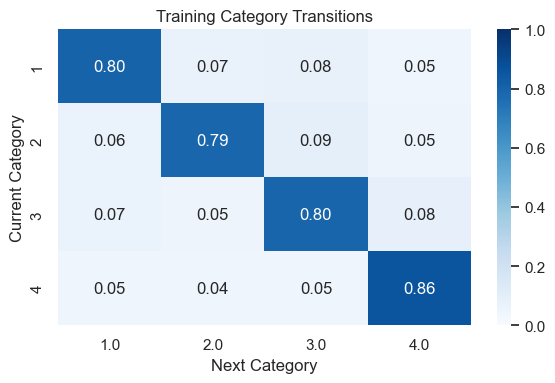

In [12]:
# Same-category rate
same_category_rate = (
    eda["CATEGORY"] == eda["Next_CATEGORY"]
).mean()

print(f"Same-category rate: {same_category_rate:.2%}")

# Products appearing in multiple categories
multi_category = (
    train_clicks.groupby("MODEL")["CATEGORY"].nunique() > 1
).sum()

print("Products with multiple categories:", multi_category)

# Category transition probabilities
category_probs = pd.crosstab(
    eda["CATEGORY"], eda["Next_CATEGORY"], normalize="index"
)

# Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(category_probs, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Training Category Transitions")
plt.xlabel("Next Category")
plt.ylabel("Current Category")
plt.tight_layout()
plt.show()

In [13]:
# Find products appearing in multiple categories
multi_category = (
    train_clicks.groupby("MODEL")["CATEGORY"].nunique()
)

multi_category = multi_category[multi_category > 1]

print("Products with multiple categories:", len(multi_category))

display(
    train_clicks[
        train_clicks["MODEL"].isin(multi_category.index)
    ][["MODEL", "CATEGORY"]]
    .drop_duplicates()
    .sort_values("MODEL")
)

Products with multiple categories: 1


,MODEL,CATEGORY
Row_ID,,
55,A18,1
19001,A18,2


In [16]:
display(
    df[df["MODEL"] == "A18"]
    .groupby(["MODEL", "CATEGORY"])
    .size()
    .reset_index(name="Count")
)

,MODEL,CATEGORY,Count
0,A18,1,937
1,A18,2,1


In [14]:
# Identify the inconsistent row
outlier = df[
    (df["MODEL"] == "A18") &
    (df["CATEGORY"] == 2)
]

display(outlier)

,YEAR,MONTH,DAY,ORDER,COUNTRY,SESSION_ID,CATEGORY,...,PRICE_2,PAGE,Next_MODEL,Previous_MODEL,Previous_2_MODEL,Price_Change,Average_Previous_Price
Row_ID,,,,,,,,,,,,,,,
19001,2008,4,10,27,29,2766,2,...,2,1,B30,B33,B28,5.0,42.269231


**Interpretation:** The same-category rate is 81.12%, indicating that users tend to continue browsing within the same category. The transition matrix confirms this pattern, with diagonal probabilities ranging from 0.79 to 0.86. Only one observation of A18 belongs to Category 2, while 937 belong to Category 1. This may indicate a data inconsistency, so the original data is retained pending further verification. Category information may be useful for next-product recommendation, but its predictive value should be evaluated using Top-K metrics.

### 6.5 Colour preferences

,Current,Next
1.0,0.048,0.047
2.0,0.181,0.182
3.0,0.179,0.166
4.0,0.100,0.101
5.0,0.010,0.011
6.0,0.103,0.110
7.0,0.041,0.043
8.0,0.017,0.010
9.0,0.082,0.086
10.0,0.022,0.020


Same-colour rate: 25.64%
Independent baseline: 11.06%


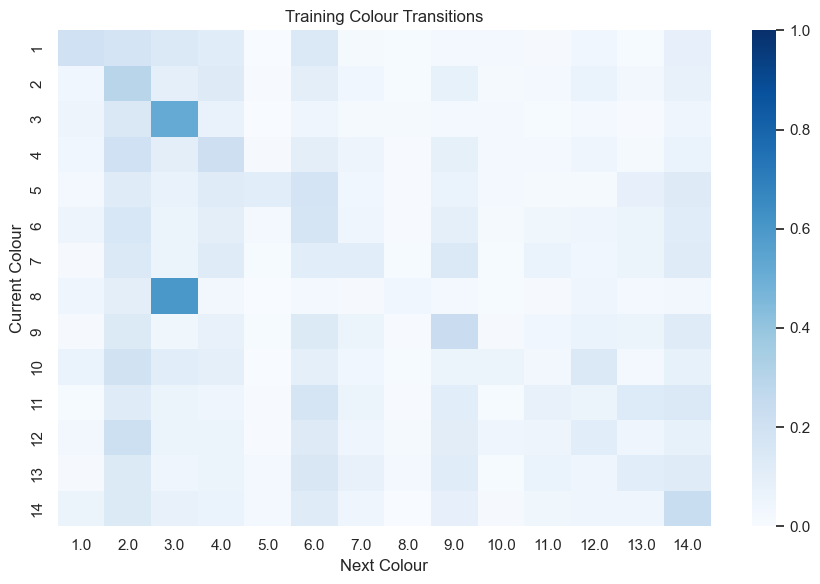

In [15]:
# Colour distributions
colour_distribution = pd.DataFrame({
    "Current": eda["COLOUR"].value_counts(normalize=True),
    "Next": eda["Next_COLOUR"].value_counts(normalize=True)
}).fillna(0)

display(colour_distribution.round(3))

# Same-colour rate and independent baseline
same_colour_rate = (
    eda["COLOUR"] == eda["Next_COLOUR"]
).mean()

independent_colour_rate = (
    colour_distribution["Current"] *
    colour_distribution["Next"]
).sum()

print(f"Same-colour rate: {same_colour_rate:.2%}")
print(f"Independent baseline: {independent_colour_rate:.2%}")

# Colour transition heatmap
colour_probs = pd.crosstab(
    eda["COLOUR"], eda["Next_COLOUR"], normalize="index"
)

plt.figure(figsize=(9, 6))
sns.heatmap(colour_probs, cmap="Blues", vmin=0, vmax=1)
plt.title("Training Colour Transitions")
plt.xlabel("Next Colour")
plt.ylabel("Current Colour")
plt.tight_layout()
plt.show()

**Interpretation:** The same-colour rate is 25.64%, considerably higher than the independent baseline of 11.06%. This suggests that consecutive clicks are more likely to involve products of the same colour than expected from the marginal colour distributions alone. The transition heatmap also shows variation across colour pairs, with some transitions occurring more frequently than others. However, this association may reflect product availability, browsing patterns, or category effects rather than an independent colour preference.

### 6.6 Price behavior

count    112491.000000
mean         43.767324
std          12.579326
min          18.000000
25%          33.000000
50%          43.000000
75%          52.000000
max          82.000000
Name: PRICE, dtype: float64

Spearman correlation: 0.188


Cheaper           0.3929
Equal             0.2175
More expensive    0.3896
dtype: float64

C:\Users\Admin\AppData\Local\Temp\ipykernel_9736\2182740005.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  eda.groupby("PRICE_2")[["PRICE", "Next_PRICE"]]


,PRICE,Next_PRICE
PRICE_2,,
1,52.92,43.69
2,34.23,43.73


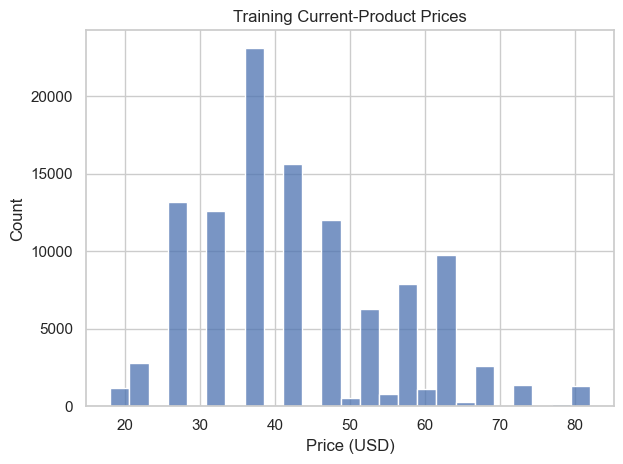

In [16]:
# Price statistics
display(eda["PRICE"].describe())

# Correlation between current and next prices
corr = eda["PRICE"].corr(eda["Next_PRICE"], method="spearman")
print(f"Spearman correlation: {corr:.3f}")

# Price changes
delta = eda["Next_PRICE"] - eda["PRICE"]

price_direction = pd.Series({
    "Cheaper": (delta < 0).mean(),
    "Equal": (delta == 0).mean(),
    "More expensive": (delta > 0).mean()
})

display(price_direction.round(4))

# Average prices by PRICE_2
display(
    eda.groupby("PRICE_2")[["PRICE", "Next_PRICE"]]
    .mean()
    .round(2)
)

# Price distribution
sns.histplot(eda["PRICE"], bins=25)
plt.title("Training Current-Product Prices")
plt.xlabel("Price (USD)")
plt.tight_layout()
plt.show()

**Interpretation:** Product prices range from $18 to $82, with an average of $43.77. The Spearman correlation between current and next-product prices is weakly positive (0.188). The proportions of clicks to cheaper (39.3%) and more expensive products (39.0%) are nearly equal. These findings suggest that price may provide some information about browsing behavior, but its contribution to next-product prediction should be verified through feature ablation and Top-K evaluation.

### 6.7 Browsing position
Early = ORDER 1–3, Middle = 4–10, Late = 11+. Stage coverage uses the same global training Top-5 list, not separate stage-specific rankings.

In [17]:
# Browsing stages
eda["Stage"] = pd.cut(
    eda["ORDER"], [0, 3, 10, np.inf],
    labels=["Early", "Middle", "Late"]
)

# Global Popularity Hit@5
top5 = target_counts.head(5).index
eda["Popularity_hit5"] = eda["Next_MODEL"].isin(top5)

display(eda["ORDER"].describe())

display(
    eda.groupby("Stage", observed=True)["Popularity_hit5"]
    .agg(["mean", "size"])
    .rename(columns={"mean": "Top5_Coverage", "size": "Clicks"})
    .round(3)
)

# Top 3 next products by browsing stage
display(
    eda.groupby("Stage", observed=True)["Next_MODEL"]
    .value_counts(normalize=True)
    .groupby(level=0).head(3)
    .rename("Proportion")
    .to_frame()
    .round(3)
)



count    112491.000000
mean         10.094772
std          13.168496
min           1.000000
25%           3.000000
50%           6.000000
75%          12.000000
max         184.000000
Name: ORDER, dtype: float64

,Top5_Coverage,Clicks
Stage,,
Early,0.102,38161
Middle,0.072,40732
Late,0.054,33598


C:\Users\Admin\AppData\Local\Temp\ipykernel_9736\3090944218.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(level=0).head(3)


Proportion
Stage  Next_MODEL            
Early  B4               0.026
       A2               0.026
       A11              0.022
Middle B4               0.020
       A10              0.015
       A11              0.014
Late   P1               0.015
       B4               0.012
       A10              0.010

**Interpretation:** Top-5 popularity coverage decreases from 10.2% in Early to 5.4% in Late, suggesting that globally popular products account for a smaller share of next clicks in later browsing stages. The most frequent next products also vary across stages, although B4 remains among the top three throughout. This suggests that browsing stage may provide useful context for next-product recommendation, but its predictive value should be verified through Top-K evaluation.

### 6.8 Geographic and temporal context

In [18]:
# Top 8 country codes
non_geographic = [12, 43, 44, 45, 46, 47]

country_counts = eda["COUNTRY"].value_counts().head(8)

display(pd.DataFrame({
    "Clicks": country_counts,
    "Type": [
        "Non-geographic" if c in non_geographic else "Geographic"
        for c in country_counts.index
    ]
}))

# Top 5 next products in the 3 most frequent geographic countries
countries = eda.loc[
    ~eda["COUNTRY"].isin(non_geographic), "COUNTRY"
].value_counts()

countries = countries[countries >= 500].head(3).index

for country in countries:
    print(f"Country {country}")
    display(
        eda.loc[eda["COUNTRY"] == country, "Next_MODEL"]
        .value_counts(normalize=True)
        .head(5)
        .rename("Proportion")
        .to_frame()
        .round(3)
    )

,Clicks,Type
COUNTRY,,
29,91157,Geographic
9,12212,Geographic
24,2837,Geographic
46,1545,Non-geographic
44,894,Non-geographic
16,673,Geographic
21,621,Geographic
34,461,Geographic


Country 29


,Proportion
Next_MODEL,
B4,0.020
P1,0.016
A11,0.014
A2,0.014
B10,0.013


Country 9


,Proportion
Next_MODEL,
A5,0.024
A12,0.023
A9,0.023
A11,0.022
A2,0.022


Country 24


,Proportion
Next_MODEL,
B4,0.022
A12,0.021
A10,0.017
A5,0.017
A2,0.014


**Interpretation:** Country 29 accounts for the largest share of clicks, followed by Countries 9 and 24. The most popular next products differ across countries: B4 ranks first in Countries 29 and 24, while A5 ranks first in Country 9. However, some products, such as A11 and A2, appear in the Top 5 across multiple countries. These differences suggest that country may provide useful context for next-product recommendation, although its predictive value should be verified through Top-K evaluation.

In [19]:
# Number of clicks by month
display(eda["MONTH"].value_counts().sort_index().rename("Clicks").to_frame())

# Top 5 next products by month
for month in sorted(eda["MONTH"].dropna().unique()):
    print(f"Month {month}")
    display(
        eda.loc[eda["MONTH"] == month, "Next_MODEL"]
        .value_counts(normalize=True)
        .head(5)
        .rename("Proportion")
        .to_frame()
        .round(3)
    )

,Clicks
MONTH,
4,32868
5,24381
6,21800
7,24069
8,9373


Month 4


,Proportion
Next_MODEL,
B4,0.020
A15,0.014
A2,0.014
P1,0.014
A4,0.013


Month 5


,Proportion
Next_MODEL,
B4,0.020
A15,0.015
B24,0.015
A11,0.014
A4,0.014


...

,Proportion
Next_MODEL,
B4,0.020
A4,0.015
A11,0.015
A2,0.014
B10,0.014


Month 7


,Proportion
Next_MODEL,
B4,0.019
A11,0.018
A2,0.018
P1,0.016
A5,0.016


Month 8


,Proportion
Next_MODEL,
A2,0.019
A11,0.018
A12,0.017
B4,0.017
A10,0.016


**Interpretation:** Click activity is highest in April (32,868 clicks) and lowest in August (9,373 clicks). B4 is the most popular next product from April to July, while A2 ranks first in August. Several products, including A11 and A2, appear frequently across multiple months, suggesting relatively stable product preferences alongside some monthly variation. However, these differences are descriptive and do not establish seasonal effects, as the dataset covers only five months. The predictive value of `MONTH` should be evaluated using Top-K metrics.



### 6.9 EDA summary


## 7. Ranking utilities
Always map score columns through the fitted `classes_`. Break ties by **lexicographic product code** for every method. SVC margins are decision scores, not probabilities; only ordering is used. Binary margins are expanded to negative/positive class columns.

MRR@10 assigns zero outside Top-10. Targets absent from fitted classes are misses. Accuracy and Macro F1 use the first ranked item, ensuring the same tie rule as Hit Rate@1. Macro F1 averages over the union of true/predicted labels; its denominator may vary across folds.

In [25]:
def rank_scores(scores, classes, k=10):
    classes = np.asarray(classes).astype(str)
    scores = np.asarray(scores)
    assert scores.ndim == 2 and scores.shape[1] == len(classes)
    assert len(set(classes)) == len(classes) and np.isfinite(scores).all()
    alphabetical = np.argsort(classes, kind="stable")
    order = np.argsort(-scores[:, alphabetical], axis=1, kind="stable")[:, :min(k, len(classes))]
    return classes[alphabetical][order]


def rank_predictions(estimator, X, k=10):
    classes = estimator.classes_
    if hasattr(estimator, "predict_proba"):
        scores = estimator.predict_proba(X)
    else:
        scores = estimator.decision_function(X)
        if np.ndim(scores) == 1:
            assert len(classes) == 2
            scores = np.column_stack([-scores, scores])
    return rank_scores(scores, classes, k)


def ranking_metrics(y, ranked):
    y = np.asarray(y).astype(str)
    assert len(y) == len(ranked) and ranked.shape[1] > 0
    matches = ranked[:, :10] == y[:, None]
    result = {f"Hit Rate@{k}": matches[:, :k].any(axis=1).mean() for k in [1, 3, 5, 10]}
    result["MRR@10"] = np.where(matches.any(axis=1), 1 / (matches.argmax(axis=1) + 1), 0).mean()
    result["Accuracy"] = accuracy_score(y, ranked[:, 0])
    result["Macro F1"] = f1_score(y, ranked[:, 0], average="macro", zero_division=0)
    assert np.isclose(result["Accuracy"], result["Hit Rate@1"])
    assert all(result[f"Hit Rate@{a}"] <= result[f"Hit Rate@{b}"] for a, b in [(1, 3), (3, 5), (5, 10)])
    assert 0 <= result["MRR@10"] <= 1
    return result


def score_estimator(estimator, X, y):
    # One prediction per partition for all metrics.
    return ranking_metrics(y, rank_predictions(estimator, X))


def hit_rate_5_scorer(estimator, X, y):
    ranked = rank_predictions(estimator, X, k=5)
    return (ranked == np.asarray(y).astype(str)[:, None]).any(axis=1).mean()


def evaluate_cv(estimator, X, y):
    result = cross_validate(estimator, X, y, cv=folds, scoring=score_estimator,
                            n_jobs=1, error_score="raise")
    return pd.DataFrame({key[5:]: value for key, value in result.items() if key.startswith("test_")},
                        index=pd.Index(range(1, 6), name="Fold"))

In [26]:
# Ties, class-column permutations, missing targets and short lists.
toy_scores = np.array([[0.5, 0.5, 0.0], [0.2, 0.2, 0.6]])
toy_classes = np.array(["B", "A", "C"])
toy_ranked = rank_scores(toy_scores, toy_classes)
assert toy_ranked.tolist() == [["A", "B", "C"], ["C", "A", "B"]]
assert np.array_equal(toy_ranked, rank_scores(toy_scores[:, [2, 0, 1]], toy_classes[[2, 0, 1]]))
assert ranking_metrics(["A", "UNSEEN"], toy_ranked)["Hit Rate@5"] == 0.5
assert ranking_metrics(["B", "A"], toy_ranked)["MRR@10"] == 0.5
assert rank_scores(np.ones((2, 1)), ["A"]).shape == (2, 1)
print("Ranking correctness checks passed.")

Ranking correctness checks passed.


## 8. Ranking baselines
Global Popularity uses training class priors. Markov estimates conditional probabilities from training-fold transitions. Unobserved transitions for known current products have zero probability; unseen current products use global training-fold popularity. Both follow the same tie rule.

In [27]:
class MarkovBaseline(ClassifierMixin, BaseEstimator):
    def fit(self, X, y):
        data = pd.DataFrame({"MODEL": X["MODEL"].to_numpy(), "Next_MODEL": np.asarray(y)})
        self.classes_ = np.sort(data["Next_MODEL"].unique())
        self.prior_ = data["Next_MODEL"].value_counts(normalize=True).reindex(self.classes_).to_numpy()
        counts = pd.crosstab(data["MODEL"], data["Next_MODEL"]).reindex(columns=self.classes_, fill_value=0)
        self.transitions_ = counts.div(counts.sum(axis=1), axis=0)
        return self

    def predict_proba(self, X):
        scores = self.transitions_.reindex(X["MODEL"].astype(object)).to_numpy().copy()
        scores[np.isnan(scores).any(axis=1)] = self.prior_
        return scores

    def predict(self, X):
        return rank_predictions(self, X, k=1)[:, 0]


baselines = {"Global Popularity": DummyClassifier(strategy="prior"), "First-Order Markov": MarkovBaseline()}
toy_markov = MarkovBaseline().fit(pd.DataFrame({"MODEL": ["A", "A", "B"]}), ["C", "D", "C"])
assert np.allclose(toy_markov.predict_proba(pd.DataFrame({"MODEL": ["NEW"]}))[0], toy_markov.prior_)
print("Markov fallback check passed.")

Markov fallback check passed.


## 9. Model comparison with grouped CV
All six methods receive the same 13-feature input and folds; baselines ignore fields they do not need. Fit preprocessing within each pipeline. START represents missing categorical history; scale numerical features for linear models only.

A multi-metric callable ranks once per partition. Select the best ML family by Hit Rate@5 then MRR@10; do not assume RF wins, or that any ML family beats the baselines.

In [28]:
model_settings = {
    "Logistic Regression": LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, tol=0.005, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=16, min_samples_leaf=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=60, max_depth=16, min_samples_leaf=5, max_features="sqrt", n_jobs=2, random_state=RANDOM_STATE),
    "LinearSVC": LinearSVC(C=1.0, max_iter=10000, tol=0.001, random_state=RANDOM_STATE)
}


def make_pipeline(model_name, features):
    cat = [f for f in features if f in categorical_features]
    num = [f for f in features if f in numerical_features]
    assert set(cat + num) == set(features)
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if model_name in ["Logistic Regression", "LinearSVC"]:
        numeric_steps.append(("scaler", StandardScaler()))
    preprocessor = ColumnTransformer([
        ("num", Pipeline(numeric_steps), num),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="START")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat)
    ])
    return Pipeline([("preprocessor", preprocessor), ("model", clone(model_settings[model_name]))])


models = {**baselines, **{name: make_pipeline(name, all_features) for name in model_settings}}
model_cv_scores = {}

In [29]:
model_cv_scores['Global Popularity'] = evaluate_cv(models['Global Popularity'], X_train, y_train)
display(model_cv_scores['Global Popularity'][["Hit Rate@5", "MRR@10", "Accuracy", "Macro F1"]].round(4))

,Hit Rate@5,MRR@10,Accuracy,Macro F1
Fold,,,,
1,0.0755,0.0461,0.0197,0.0002
2,0.0739,0.0452,0.0192,0.0002
3,0.0788,0.0478,0.0201,0.0002
4,0.0760,0.0461,0.0195,0.0002
5,0.0774,0.0467,0.0197,0.0002


In [30]:
model_cv_scores['First-Order Markov'] = evaluate_cv(models['First-Order Markov'], X_train, y_train)
display(model_cv_scores['First-Order Markov'][["Hit Rate@5", "MRR@10", "Accuracy", "Macro F1"]].round(4))

,Hit Rate@5,MRR@10,Accuracy,Macro F1
Fold,,,,
1,0.3656,0.2324,0.1294,0.0878
2,0.3664,0.2310,0.1280,0.0869
3,0.3641,0.2334,0.1321,0.0915
4,0.3677,0.2332,0.1310,0.0932
5,0.3642,0.2293,0.1253,0.0858


In [31]:
model_cv_scores['Logistic Regression'] = evaluate_cv(models['Logistic Regression'], X_train, y_train)
display(model_cv_scores['Logistic Regression'][["Hit Rate@5", "MRR@10", "Accuracy", "Macro F1"]].round(4))

,Hit Rate@5,MRR@10,Accuracy,Macro F1
Fold,,,,
1,0.3474,0.2219,0.1244,0.0784
2,0.3472,0.2208,0.1236,0.0779
3,0.3439,0.2221,0.1268,0.0788
4,0.3491,0.2220,0.1249,0.0762
5,0.3467,0.2201,0.1227,0.0756


In [32]:
model_cv_scores['Decision Tree'] = evaluate_cv(models['Decision Tree'], X_train, y_train)
display(model_cv_scores['Decision Tree'][["Hit Rate@5", "MRR@10", "Accuracy", "Macro F1"]].round(4))

,Hit Rate@5,MRR@10,Accuracy,Macro F1
Fold,,,,
1,0.3092,0.2047,0.1221,0.0980
2,0.3094,0.2026,0.1195,0.1030
3,0.3144,0.2070,0.1246,0.1038
4,0.3113,0.2045,0.1213,0.1048
5,0.3060,0.2033,0.1219,0.0976


In [33]:
model_cv_scores['Random Forest'] = evaluate_cv(models['Random Forest'], X_train, y_train)
display(model_cv_scores['Random Forest'][["Hit Rate@5", "MRR@10", "Accuracy", "Macro F1"]].round(4))

,Hit Rate@5,MRR@10,Accuracy,Macro F1
Fold,,,,
1,0.3642,0.2348,0.1344,0.0962
2,0.3652,0.2352,0.1353,0.0978
3,0.3649,0.2370,0.1388,0.1015
4,0.3668,0.2383,0.1394,0.1050
5,0.3632,0.2327,0.1315,0.0915


In [34]:
model_cv_scores['LinearSVC'] = evaluate_cv(models['LinearSVC'], X_train, y_train)
display(model_cv_scores['LinearSVC'][["Hit Rate@5", "MRR@10", "Accuracy", "Macro F1"]].round(4))

,Hit Rate@5,MRR@10,Accuracy,Macro F1
Fold,,,,
1,0.3382,0.2191,0.1282,0.1016
2,0.3399,0.2190,0.1288,0.1027
3,0.3355,0.2205,0.1320,0.1056
4,0.3395,0.2222,0.1317,0.1070
5,0.3361,0.2167,0.1257,0.0982


In [36]:
model_comparison = pd.DataFrame({name: scores.mean() for name, scores in model_cv_scores.items()}).T
model_comparison["HR5_std"] = pd.Series({name: scores["Hit Rate@5"].std() for name, scores in model_cv_scores.items()})
model_comparison = model_comparison.sort_values(["Hit Rate@5", "MRR@10"], ascending=False, kind="stable")
display(model_comparison[["Hit Rate@5", "HR5_std", "MRR@10", "Accuracy", "Macro F1"]].round(4))
selected_name = model_comparison.loc[model_comparison.index.isin(model_settings)].index[0]
display(Markdown(f"**Selection:** {selected_name} leads the ML families by CV Hit Rate@5 ({model_comparison.loc[selected_name, 'Hit Rate@5']:.2%}), with MRR@10 {model_comparison.loc[selected_name, 'MRR@10']:.4f}. The baseline results remain visible even if they win. Standard deviations describe fold variability, not confidence intervals."))

,Hit Rate@5,HR5_std,MRR@10,Accuracy,Macro F1
First-Order Markov,0.3656,0.0015,0.2319,0.1292,0.0890
Random Forest,0.3649,0.0013,0.2356,0.1359,0.0984
Logistic Regression,0.3469,0.0019,0.2214,0.1245,0.0774
LinearSVC,0.3378,0.0020,0.2195,0.1293,0.1030
Decision Tree,0.3101,0.0031,0.2044,0.1219,0.1015
Global Popularity,0.0763,0.0019,0.0464,0.0196,0.0002


**Selection:** Random Forest leads the ML families by CV Hit Rate@5 (36.49%), with MRR@10 0.2356. The baseline results remain visible even if they win. Standard deviations describe fold variability, not confidence intervals.

## 10. Feature ablation
Use the selected family with unchanged parameters and folds. Reuse E4 scores from model comparison. E5 tests product history without context. Select by Hit Rate@5, then MRR@10, then fewer features; never consult test performance.

In [37]:
experiment_features = {
    "E1": product_features,
    "E2": product_features + context_features,
    "E3": product_features + context_features + product_history,
    "E4": all_features,
    "E5": product_features + product_history
}
ablation_scores = {"E4": model_cv_scores[selected_name].copy()}

In [38]:
ablation_scores['E1'] = evaluate_cv(
    make_pipeline(selected_name, experiment_features['E1']),
    train_df[experiment_features['E1']], y_train
)
display(ablation_scores['E1'][["Hit Rate@5", "MRR@10", "Accuracy"]].round(4))

,Hit Rate@5,MRR@10,Accuracy
Fold,,,
1,0.3625,0.2299,0.1275
2,0.3625,0.2271,0.1258
3,0.3607,0.2308,0.1309
4,0.3627,0.2297,0.1283
5,0.3538,0.2241,0.1239


In [39]:
ablation_scores['E2'] = evaluate_cv(
    make_pipeline(selected_name, experiment_features['E2']),
    train_df[experiment_features['E2']], y_train
)
display(ablation_scores['E2'][["Hit Rate@5", "MRR@10", "Accuracy"]].round(4))

,Hit Rate@5,MRR@10,Accuracy
Fold,,,
1,0.3437,0.2199,0.1247
2,0.3435,0.2197,0.1241
3,0.3443,0.2220,0.1275
4,0.3466,0.2224,0.1268
5,0.3393,0.2172,0.1214


In [40]:
ablation_scores['E3'] = evaluate_cv(
    make_pipeline(selected_name, experiment_features['E3']),
    train_df[experiment_features['E3']], y_train
)
display(ablation_scores['E3'][["Hit Rate@5", "MRR@10", "Accuracy"]].round(4))

,Hit Rate@5,MRR@10,Accuracy
Fold,,,
1,0.3628,0.2345,0.1355
2,0.3655,0.2333,0.1333
3,0.3652,0.2352,0.1365
4,0.3648,0.2370,0.1386
5,0.3637,0.2328,0.1317


In [41]:
ablation_scores['E5'] = evaluate_cv(
    make_pipeline(selected_name, experiment_features['E5']),
    train_df[experiment_features['E5']], y_train
)
display(ablation_scores['E5'][["Hit Rate@5", "MRR@10", "Accuracy"]].round(4))

,Hit Rate@5,MRR@10,Accuracy
Fold,,,
1,0.3393,0.2194,0.1272
2,0.3394,0.2187,0.1274
3,0.3378,0.2186,0.1275
4,0.3387,0.2219,0.1309
5,0.3381,0.2165,0.1237


,Features,Hit Rate@5,HR5_std,MRR@10,Accuracy,HR5_gain_vs_E1_pp
E1,5,0.3604,0.0038,0.2283,0.1273,0.0000
E2,9,0.3435,0.0027,0.2202,0.1249,-1.6979
E3,11,0.3644,0.0012,0.2346,0.1351,0.3983
E4,13,0.3649,0.0013,0.2356,0.1359,0.4436
E5,7,0.3387,0.0007,0.2190,0.1273,-2.1780


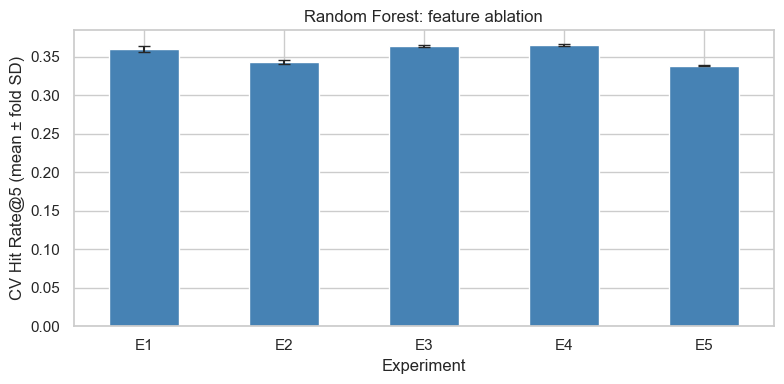

,HR5_difference_pp
Context: E2 minus E1,-1.698
History with context: E3 minus E2,2.096
Price history: E4 minus E3,0.045
History alone: E5 minus E1,-2.178


**Selection:** E4 (13 features) wins under the predefined CV rule. Signed differences show which groups help or hurt this family. These paired comparisons use identical folds, but do not establish statistical significance or causation.

In [42]:
ablation_table = pd.DataFrame({name: scores.mean() for name, scores in ablation_scores.items()}).T.sort_index()
ablation_table["HR5_std"] = pd.Series({name: scores["Hit Rate@5"].std() for name, scores in ablation_scores.items()})
ablation_table["Features"] = pd.Series({name: len(features) for name, features in experiment_features.items()})
ablation_table["HR5_gain_vs_E1_pp"] = 100 * (ablation_table["Hit Rate@5"] - ablation_table.loc["E1", "Hit Rate@5"])
display(ablation_table[["Features", "Hit Rate@5", "HR5_std", "MRR@10", "Accuracy", "HR5_gain_vs_E1_pp"]].round(4))
selected_experiment = ablation_table.sort_values(["Hit Rate@5", "MRR@10", "Features"], ascending=[False, False, True], kind="stable").index[0]
selected_features = experiment_features[selected_experiment].copy()
fig, ax = plt.subplots(figsize=(8, 4))
ablation_table["Hit Rate@5"].plot.bar(yerr=ablation_table["HR5_std"], capsize=4, color="steelblue", ax=ax)
ax.set(title=f"{selected_name}: feature ablation", xlabel="Experiment", ylabel="CV Hit Rate@5 (mean ± fold SD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
feature_effects = pd.Series({
    "Context: E2 minus E1": 100 * (ablation_table.loc["E2", "Hit Rate@5"] - ablation_table.loc["E1", "Hit Rate@5"]),
    "History with context: E3 minus E2": 100 * (ablation_table.loc["E3", "Hit Rate@5"] - ablation_table.loc["E2", "Hit Rate@5"]),
    "Price history: E4 minus E3": 100 * (ablation_table.loc["E4", "Hit Rate@5"] - ablation_table.loc["E3", "Hit Rate@5"]),
    "History alone: E5 minus E1": 100 * (ablation_table.loc["E5", "Hit Rate@5"] - ablation_table.loc["E1", "Hit Rate@5"])
}, name="HR5_difference_pp")
display(feature_effects.to_frame().round(3))
display(Markdown(f"**Selection:** {selected_experiment} ({len(selected_features)} features) wins under the predefined CV rule. Signed differences show which groups help or hurt this family. These paired comparisons use identical folds, but do not establish statistical significance or causation."))

## 11. Compact hyperparameter search
Test three predeclared configurations for the selected family, including the untuned configuration. This bounded RandomizedSearchCV samples all three candidates. Pass session groups to GroupKFold and verify its folds match the earlier list. Optimize and refit **Hit Rate@5**; other metrics are diagnostic. The search already refits on full train, so no second full-training fit is needed.

In [43]:
from sklearn.model_selection import RandomizedSearchCV

X_train_selected = train_df[selected_features]

param_space = {
    "model__n_estimators":      [60, 100, 150],
    "model__max_depth":         [12, 16, 20, 24],
    "model__min_samples_leaf":  [1, 2, 3, 5, 10],
    "model__min_samples_split": [2, 5, 10],
    "model__max_features":      ["sqrt", "log2", 0.3],
    "model__max_samples":       [None, 0.7, 0.9],
}

def mrr10_scorer(estimator, X, y):
    return ranking_metrics(y, rank_predictions(estimator, X))["MRR@10"]

search = RandomizedSearchCV(
    make_pipeline(selected_name, selected_features),
    param_space,
    n_iter=10,
    scoring={"Hit Rate@5": hit_rate_5_scorer, "MRR@10": mrr10_scorer},
    refit="Hit Rate@5",
    cv=folds,                 # dùng thẳng 5 fold đã tạo, không cần groups
    random_state=RANDOM_STATE,
    n_jobs=1,
    error_score="raise",
)
search.fit(X_train_selected, y_train)

best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

tuning_results = (
    pd.DataFrame(search.cv_results_)
    [["rank_test_Hit Rate@5", "mean_test_Hit Rate@5", "std_test_Hit Rate@5",
      "mean_test_MRR@10", "mean_fit_time", "params"]]
    .sort_values("rank_test_Hit Rate@5")
)
pd.set_option("display.max_colwidth", None)
display(tuning_results.round(4))

untuned_hr5 = ablation_table.loc[selected_experiment, "Hit Rate@5"]
display(Markdown(
    f"**Interpretation:** Untuned CV Hit Rate@5 is {untuned_hr5:.2%}; "
    f"the best searched value is {search.best_score_:.2%}, "
    f"a change of {100 * (search.best_score_ - untuned_hr5):+.3f} pp. "
    "This is training-CV evidence only; reusing folds can make it optimistic."
))

Best parameters: {'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 3, 'model__max_samples': None, 'model__max_features': 'sqrt', 'model__max_depth': 24}


,rank_test_Hit Rate@5,mean_test_Hit Rate@5,std_test_Hit Rate@5,mean_test_MRR@10,mean_fit_time,params
9,1,0.3740,0.0011,0.2429,29.8101,"{'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 3, 'model__max_samples': None, 'model__max_features': 'sqrt', 'model__max_depth': 24}"
3,2,0.3728,0.0009,0.2411,11.7458,"{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_samples': 0.7, 'model__max_features': 'sqrt', 'model__max_depth': 24}"
2,3,0.3702,0.0017,0.2416,30.4212,"{'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_samples': 0.7, 'model__max_features': 'sqrt', 'model__max_depth': 20}"
8,4,0.3677,0.0008,0.2377,9.0383,"{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_samples': 0.7, 'model__max_features': 'sqrt', 'model__max_depth': 16}"
4,5,0.3647,0.0018,0.2391,141.3610,"{'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_samples': 0.7, 'model__max_features': 0.3, 'model__max_depth': 20}"
0,6,0.3622,0.0020,0.2363,121.4801,"{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_samples': 0.7, 'model__max_features': 0.3, 'model__max_depth': 20}"
1,7,0.3613,0.0013,0.2328,5.3829,"{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 3, 'model__max_samples': 0.9, 'model__max_features': 'log2', 'model__max_depth': 24}"
5,8,0.3599,0.0013,0.2367,61.1520,"{'model__n_estimators': 60, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_samples': None, 'model__max_features': 0.3, 'model__max_depth': 20}"
7,9,0.3528,0.0010,0.2270,5.0101,"{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_samples': 0.9, 'model__max_features': 'sqrt', 'model__max_depth': 12}"
6,10,0.3511,0.0030,0.2261,3.3542,"{'model__n_estimators': 60, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_samples': 0.9, 'model__max_features': 'log2', 'model__max_depth': 20}"


**Interpretation:** Untuned CV Hit Rate@5 is 36.49%; the best searched value is 37.40%, a change of +0.917 pp. This is training-CV evidence only; reusing folds can make it optimistic.

## 12. Final held-out test evaluation
Freeze model, features and parameters first. Evaluate the tuned model and both baselines on identical test rows, generating each ranking once and reusing it. Keep unseen targets as misses.

This is the previously inspected holdout under a newly declared ranking objective, not fresh confirmation. No choices are revised using test results.

,Accuracy,Macro F1,Hit Rate@1,Hit Rate@3,Hit Rate@5,Hit Rate@10,MRR@10
Global Popularity,0.0175,0.0002,0.0175,0.0484,0.0760,0.1407,0.0451
First-Order Markov,0.1314,0.0920,0.1314,0.2761,0.3750,0.5361,0.2376
Untuned Random Forest,0.1391,0.1019,0.1391,0.2802,0.3743,0.5283,0.2416
Tuned Random Forest,0.1476,0.1243,0.1476,0.2918,0.3858,0.5411,0.2513


Test targets absent from fitted ML classes: ['P54']
Their test rows (retained): 1


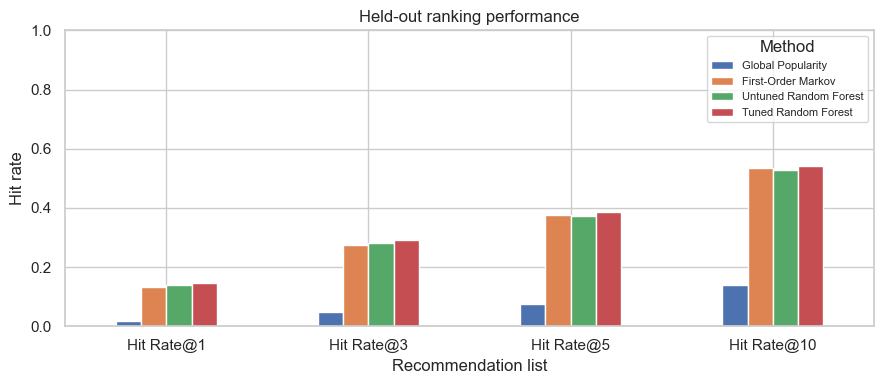

**Interpretation:** Tuned Random Forest achieves 38.58% test Hit Rate@5: +1.08 pp vs Markov and +1.15 pp vs Untuned Random Forest. Negative differences mean the comparison model wins. Test results are descriptive only and are not used to revise selection.

In [44]:
# ---------- 1. Chuẩn bị dữ liệu test ----------
y_test = test_df["Next_MODEL"]
X_test_all = test_df[all_features]          # cho 2 baseline
X_test_sel = test_df[selected_features]     # cho model RF
assert X_test_sel.index.equals(y_test.index)

# ---------- 2. Các estimator đã đóng băng ----------
ml_label = "Tuned " + selected_name
untuned_label = "Untuned " + selected_name

final_estimators = {name: clone(est).fit(X_train, y_train) for name, est in baselines.items()}
final_estimators[untuned_label] = make_pipeline(selected_name, selected_features).fit(X_train_selected, y_train)
final_estimators[ml_label] = best_model      # đã refit trên toàn bộ train bởi RandomizedSearchCV

# ---------- 3. Xếp hạng 1 lần cho mỗi model ----------
test_rankings = {}
for name, est in final_estimators.items():
    X_eval = X_test_sel if name in (ml_label, untuned_label) else X_test_all
    test_rankings[name] = rank_predictions(est, X_eval)

# ---------- 4. Bảng kết quả ----------
test_results = pd.DataFrame(
    {name: ranking_metrics(y_test, ranked) for name, ranked in test_rankings.items()}
).T
metric_order = ["Accuracy", "Macro F1", "Hit Rate@1", "Hit Rate@3", "Hit Rate@5", "Hit Rate@10", "MRR@10"]
display(test_results[metric_order].round(4))

# ---------- 5. Nhãn chưa từng xuất hiện trong train ----------
unseen_test_classes = sorted(set(y_test) - set(best_model.classes_))
print("Test targets absent from fitted ML classes:", unseen_test_classes)
print("Their test rows (retained):", y_test.isin(unseen_test_classes).sum())
assert not np.isin(np.asarray(unseen_test_classes), test_rankings[ml_label]).any()

# ---------- 6. Biểu đồ ----------
hit_cols = ["Hit Rate@1", "Hit Rate@3", "Hit Rate@5", "Hit Rate@10"]
fig, ax = plt.subplots(figsize=(9, 4))
test_results[hit_cols].T.plot.bar(ax=ax)
ax.set(title="Held-out ranking performance", xlabel="Recommendation list",
       ylabel="Hit rate", ylim=(0, 1))
plt.xticks(rotation=0)
plt.legend(title="Method", fontsize=8)
plt.tight_layout()
plt.show()

# ---------- 7. Diễn giải ----------
hr5 = test_results["Hit Rate@5"]
vs_markov = 100 * (hr5[ml_label] - hr5["First-Order Markov"])
vs_untuned = 100 * (hr5[ml_label] - hr5[untuned_label])
display(Markdown(
    f"**Interpretation:** {ml_label} achieves {hr5[ml_label]:.2%} test Hit Rate@5: "
    f"{vs_markov:+.2f} pp vs Markov and {vs_untuned:+.2f} pp vs {untuned_label}. "
    "Negative differences mean the comparison model wins. "
    "Test results are descriptive only and are not used to revise selection."
))

**Held-out test results.** Tuned Random Forest reaches a test Hit Rate@5 of 38.58%, which is 1.08 pp above First-Order Markov (37.50%) and 1.15 pp above Untuned Random Forest (37.43%). It ranks first at every K (Hit Rate@1/3/5/10) and on MRR@10, and it also has the highest Macro F1 (0.1243, versus 0.0920 for Markov). Global Popularity is very weak (Hit Rate@5 = 7.60%), confirming that a single context-free list can hardly predict the next click.

**Observations.**
- The advantage of Tuned RF over Markov is largest at Top-1 (+1.62 pp) and Top-3 (+1.57 pp) and shrinks at Top-5 (+1.08 pp) and Top-10 (+0.50 pp). As the list grows, Markov already covers most plausible candidates, leaving less room for ML to improve.
- Untuned RF is essentially tied with Markov at Hit Rate@5 (37.43% vs 37.50%) and falls below it at Hit Rate@10, so most of the ML advantage comes from tuning. The tuning gain on test (+1.15 pp) has the same direction and a similar size as the gain in CV (+0.92 pp).
- Differences of about 1 pp are small. With 28,957 test rows, the standard error of a Hit Rate near 0.38 is roughly 0.3 pp, and rows from the same session are not independent, so the true uncertainty is larger. No significance test was performed.
- Product P54 appears only in the test set (1 row), so no model can recommend it; the row is retained and counted as a miss.

**Cautious conclusion.** Tuned RF gives a small but consistent improvement over Markov on the held-out test set, while Markov remains a strong and much simpler baseline. This holdout was already inspected in the earlier Accuracy-oriented analysis, so these results are descriptive only and are not used to revise model or parameter selection.

## 13. Top-K error analysis
Reuse the frozen ML rankings. Descriptive error analysis does not trigger new tuning.

### 13.1 Hit Rate@5 by browsing stage

In [45]:
ml_ranked = test_rankings[ml_label]
hit5 = (ml_ranked[:, :5] == y_test.to_numpy()[:, None]).any(axis=1)

error_df = test_df[["ORDER", "CATEGORY", "Next_MODEL"]].assign(
    Hit5=hit5,
    Stage=pd.cut(test_df["ORDER"], [0, 3, 10, np.inf], labels=["Early", "Middle", "Late"]),
)

stage_results = (
    error_df.groupby("Stage", observed=True)["Hit5"]
    .agg(**{"Hit Rate@5": "mean", "Clicks": "size"})
)
display(stage_results.round(4))

,Hit Rate@5,Clicks
Stage,,
Early,0.3616,9531
Middle,0.3685,10329
Late,0.4310,9097


**Observations.** Hit Rate@5 is similar in the Early (36.2%) and Middle (36.9%) stages and higher in the Late stage (43.1%), about 7 pp above the other two. The three stages have comparable numbers of test clicks (9,097 to 10,329), so the gap is not driven by one very small group. A plausible explanation is that later clicks follow more regular browsing sequences (e.g., consecutive products in the same category) and carry more history, which makes the next product easier to rank. This is an association with click position and sample composition, not evidence that longer sessions cause better predictions. Long sessions also contribute more rows, so the Late group is dominated by a relatively small number of sessions.



### 13.2 Hit Rate@5 by current product category

In [46]:
category_results = error_df.groupby("CATEGORY", observed=True)["Hit5"].agg(["mean", "size"]).rename(columns={"mean": "Hit Rate@5", "size": "Clicks"})
display(category_results.round(4))

,Hit Rate@5,Clicks
CATEGORY,,
1,0.4143,9033
2,0.4061,6474
3,0.3350,6771
4,0.3794,6679


**Observations.** Hit Rate@5 varies by the category of the current product: it is highest for Category 1 (41.4%) and Category 2 (40.6%), lower for Category 4 (37.9%), and lowest for Category 3 (33.5%), a gap of about 8 pp between the best and worst groups. All four groups have substantial support (6,474 to 9,033 clicks), so the differences are not driven by a tiny group. Category 3 is the hardest to rank, possibly because its products are followed by a more dispersed set of next products, but this was not tested here. These rates describe the category of the current product, not a restriction on the next category (about 81% of next clicks stay in the same category in the training EDA). Differences may also reflect how products and sessions are distributed across categories, so they should not be read as a causal effect of category.



### 13.3 Frequently missed products

In [47]:
missed_products = error_df.groupby("Next_MODEL")["Hit5"].agg(["size", "sum", "mean"])
missed_products["Misses"] = missed_products["size"] - missed_products["sum"]
missed_products = missed_products.rename(columns={"size": "Test_clicks", "sum": "Hits", "mean": "Hit Rate@5"})
display(missed_products.sort_values("Misses", ascending=False).head(15).round(4))

,Test_clicks,Hits,Hit Rate@5,Misses
Next_MODEL,,,,
B4,506,184,0.3636,322
P1,391,135,0.3453,256
A4,347,105,0.3026,242
A2,454,214,0.4714,240
A15,375,152,0.4053,223
A1,215,10,0.0465,205
A5,424,236,0.5566,188
B1,194,6,0.0309,188
A13,237,59,0.2489,178


**Observations.** Misses are concentrated in products that are both frequent and hard to rank. Two groups stand out:
- **Frequent products with moderate Hit Rate@5** (B4, P1, A4, A15, C5): they have many test clicks (292 to 506) and Hit Rate@5 of 30% to 41%, so they produce the most misses mainly because of volume, not because they are unusually difficult.
- **Products that are almost never recommended in the Top-5** (A1: 4.7%, B1: 3.1%): despite 215 and 194 test clicks, only 10 and 6 are hits. These are consistently hard cases, and they account for about 190 to 205 misses each, far more than their frequency alone would suggest.

In contrast, A5 (55.7%), A11 (62.1%), B10 (56.7%), A10 (63.2%) and A3 (52.1%) are ranked well, and several appear in this table only because they have many clicks. A13 (24.9%) is also below average.



In [48]:
for p in ["A1", "B1"]:
    sub = test_df[test_df["Next_MODEL"] == p]
    print(p, "- ORDER của click TRƯỚC đáp án (median):", sub["ORDER"].median())
    print(sub["MODEL"].value_counts().head(5), "\n")

A1 - ORDER của click TRƯỚC đáp án (median): 3.0
MODEL
A2     24
A11    17
A1     16
A4     14
A3     10
Name: count, dtype: int64 

B1 - ORDER của click TRƯỚC đáp án (median): 5.0
MODEL
B4     18
B16    10
B1     10
B17     9
B10     8
Name: count, dtype: int64 



**Follow-up check on A1 and B1.** The current click preceding A1 and B1 has a median ORDER of 3 and 5, so these are not simply first-click products. The preceding product is widely dispersed (for A1: A2, A11, A1, A4, A3 account for only about 80 of 215 rows; B1 is even more dispersed), so neither the current product nor short history gives a strong signal. A1 and B1 also frequently follow themselves (16 and 10 rows), and A1 often follows later products such as A2, which may reflect return or back-navigation behaviour. This is a hypothesis consistent with the pattern, not a tested explanation, since the data has no explicit back-navigation indicator.



### 13.4 Prediction concentration and catalogue coverage
Eligible catalogue products are codes observed in complete training sessions, including training targets. This denominator is fixed without test labels. An unseen test product still counts as a metric miss. Catalogue Coverage@5 is the fraction of these training-known products recommended at least once.

In [49]:
# Mỗi dòng test có 5 gợi ý (5 "slot"); đếm mỗi sản phẩm xuất hiện bao nhiêu slot
top5 = ml_ranked[:, :5].ravel()
slot_counts = pd.Series(top5).value_counts()
total_slots = slot_counts.sum()

# Danh mục hợp lệ: sản phẩm xuất hiện trong train
catalogue = set(train_clicks["MODEL"]) | set(y_train)
assert set(slot_counts.index) <= catalogue

# Các chỉ số
coverage = len(slot_counts) / len(catalogue)                       # % sản phẩm được gợi ý ít nhất 1 lần
top10_model_share = slot_counts.head(10).sum() / total_slots       # 10 sản phẩm được gợi ý nhiều nhất chiếm bao nhiêu slot
top10_train = target_counts.head(10).index                         # 10 sản phẩm phổ biến nhất ở train
top10_train_share = slot_counts[slot_counts.index.isin(top10_train)].sum() / total_slots

summary = pd.Series({
    "Eligible_products": len(catalogue),
    "Distinct_recommended": len(slot_counts),
    "Catalogue_Coverage@5": coverage,
    "Top10_recommended_slot_share": top10_model_share,
    "Top10_train_popular_slot_share": top10_train_share,
})
display(summary.to_frame("Value").round(4))

# 10 sản phẩm được gợi ý nhiều nhất
display(pd.DataFrame({
    "Slots": slot_counts.head(10),
    "Slot_share": slot_counts.head(10) / total_slots,
}).round(4))

display(Markdown(
    f"**Interpretation:** Top-5 lists cover {coverage:.1%} of {len(catalogue)} eligible products. "
    f"The ten most popular training targets receive {top10_train_share:.1%} of slots. "
    "Coverage and concentration describe different properties; "
    "neither alone establishes relevance, diversity or satisfaction."
))

,Value
Eligible_products,216.0000
Distinct_recommended,213.0000
Catalogue_Coverage@5,0.9861
Top10_recommended_slot_share,0.1816
Top10_train_popular_slot_share,0.1673


,Slots,Slot_share
A11,4146,0.0286
B10,2893,0.0200
A10,2854,0.0197
B4,2719,0.0188
C17,2662,0.0184
A5,2408,0.0166
A9,2330,0.0161
A12,2189,0.0151
B24,2151,0.0149
A15,1947,0.0134


**Interpretation:** Top-5 lists cover 98.6% of 216 eligible products. The ten most popular training targets receive 16.7% of slots. Coverage and concentration describe different properties; neither alone establishes relevance, diversity or satisfaction.

**Observations.** The tuned model recommends 213 of 216 eligible products at least once (Catalogue Coverage@5 = 98.6%), and the ten most recommended products take only 18.2% of all slots; the top product (A11) takes 2.9%. The ten most popular training targets receive 16.7% of slots, so the model is not simply repeating a global popularity list, unlike Global Popularity, which would recommend the same five products to every click. High coverage and low concentration do not imply relevance or user satisfaction, and per-list diversity was not measured.

## 14. Permutation importance for Hit Rate@5
Refit the tuned configuration on training fold 1 and assess importance on up to 3,000 validation rows from that fold, sampled with the fixed seed. Use three permutations and Hit Rate@5. This bounds computation without using test data or deleting features.

The fold already participated in model/parameter selection, so this is exploratory. Independently shuffling MODEL, CATEGORY or layout can create unrealistic combinations. Importance measures sensitivity, not independent or causal contributions. Repeat variability is not uncertainty across sessions.

In [50]:
importance_tr, importance_va = folds[0]
importance_model = clone(best_model).fit(X_train_selected.iloc[importance_tr], y_train.iloc[importance_tr])
importance_rows = np.random.default_rng(RANDOM_STATE).choice(importance_va, size=min(3000, len(importance_va)), replace=False)
importance = permutation_importance(
    importance_model, X_train_selected.iloc[importance_rows], y_train.iloc[importance_rows],
    scoring=hit_rate_5_scorer, n_repeats=3, random_state=RANDOM_STATE, n_jobs=1
)
importance_df = pd.DataFrame({"Feature": selected_features, "HR5_decrease": importance.importances_mean,
                              "Repeat_SD": importance.importances_std}).sort_values("HR5_decrease", ascending=False)
display(importance_df.round(4))
display(Markdown(f"**Interpretation:** The largest average perturbation effect here is for **{importance_df.iloc[0]['Feature']}**. Correlation and validation sampling affect the ordering; small or negative values alone do not justify removing a feature."))

,Feature,HR5_decrease,Repeat_SD
1,CATEGORY,0.1309,0.0024
6,PAGE,0.0234,0.0018
2,COLOUR,0.0116,0.0018
7,LOCATION,0.0110,0.0026
0,MODEL,0.0094,0.0015
3,PRICE,0.0073,0.0005
8,PHOTOGRAPHY,0.0066,0.0023
4,PRICE_2,0.0029,0.0006
9,Previous_MODEL,0.0018,0.0020
12,Average_Previous_Price,0.0008,0.0020


**Interpretation:** The largest average perturbation effect here is for **CATEGORY**. Correlation and validation sampling affect the ordering; small or negative values alone do not justify removing a feature.

**Observations.** Shuffling CATEGORY lowers fold-1 Hit Rate@5 by about 13.1 pp, roughly five times the next feature (PAGE, 2.3 pp), which is consistent with the EDA finding that about 81% of next clicks stay in the same category. COLOUR, LOCATION, PAGE, MODEL and PRICE show smaller effects (about 0.7 to 2.3 pp). History features (Previous_MODEL, Previous_2_MODEL, Price_Change, Average_Previous_Price) and ORDER are close to zero, within or near the repeat SD, so their small or negative values are noise and not evidence that they are harmful or useless.

**How to interpret these values.**
- **Not independent or causal contributions.** Permutation importance measures how sensitive the fitted model is to one column. When features carry overlapping information (for example, MODEL codes such as A/B/C/P map to a category, and PRICE and COLOUR also relate to product identity), shuffling one column lets the others partly compensate, so the importance of each correlated feature is understated and the ranking among them is unreliable. MODEL's modest score (0.9 pp) likely reflects this redundancy, not low relevance, as Markov, which uses only MODEL, already reaches about 37% Hit Rate@5.
- **Unrealistic combinations.** Shuffling one column independently creates rows that do not exist in the data (for example, product A5 labelled with Category 4). The model may react strongly to such contradictions, so part of CATEGORY's large drop may reflect this artefact and not only its true predictive value.
- **Exploratory scope.** Importance was computed on one fold with 3,000 sampled rows and three repeats. Fold 1 also took part in model and parameter selection, so it is not fully independent, and the ordering among low-importance features is unstable across runs.
- **Repeat SD is not session-level uncertainty.** It only measures variation across the three shuffles on the same rows and does not capture variation across sessions or samples.

These results are therefore descriptive: they show which columns the tuned model relies on, and they do not justify removing features. The ablation study remains the more direct evidence for feature-group value, and it still showed a gain from adding product history to context (E3 vs E2).

## 15. Discussion and conclusion
Answers below are generated from this notebook's results, distinguishing CV from held-out test performance.

In [51]:
cv_best_ml = model_comparison.loc[selected_name, "Hit Rate@5"]
cv_popularity = model_comparison.loc["Global Popularity", "Hit Rate@5"]
cv_markov = model_comparison.loc["First-Order Markov", "Hit Rate@5"]
test_ml = test_results.loc[ml_label]
test_markov = test_results.loc["First-Order Markov"]
beats_baselines = test_ml["Hit Rate@5"] > test_results.loc[list(baselines), "Hit Rate@5"].max()
display(Markdown(f"""### RQ1. Do ML models outperform the baselines?
On grouped CV, **{selected_name}** leads ML families at **{cv_best_ml:.2%} Hit Rate@5**, compared with **{cv_popularity:.2%}** for Popularity and **{cv_markov:.2%}** for Markov. After CV-based ablation and tuning, the frozen ML model **{'outperforms both baselines' if beats_baselines else 'does not outperform both baselines'}** on test Hit Rate@5. The final table retains cases where simpler methods match or win.

### RQ2. Does context or history improve ranking?
Adding context to current products changes CV Hit Rate@5 by **{feature_effects['Context: E2 minus E1']:+.3f} pp**. Adding history above context changes it by **{feature_effects['History with context: E3 minus E2']:+.3f} pp**; price history changes it by **{feature_effects['Price history: E4 minus E3']:+.3f} pp**. History without context changes it by **{feature_effects['History alone: E5 minus E1']:+.3f} pp**. **{selected_experiment}** is selected using CV only. These are conditional ablation differences, not universal or statistically proven effects.

### RQ3. How effectively is the next product ranked?
The selected ML model obtains test Hit Rate@1 **{test_ml['Hit Rate@1']:.2%}**, Hit Rate@5 **{test_ml['Hit Rate@5']:.2%}**, Hit Rate@10 **{test_ml['Hit Rate@10']:.2%}** and MRR@10 **{test_ml['MRR@10']:.4f}**. Markov obtains **{test_markov['Hit Rate@5']:.2%}** at K=5 and **{test_markov['MRR@10']:.4f}** MRR@10. Hit Rate@5 matches a five-item list more directly than Top-1 Accuracy; MRR distinguishes early placement from merely including the target.

### Practical meaning
Popularity matters, but a global list ignores browsing context. Markov gives inexpensive conditional rankings; ML adds preprocessing, fitting and inference complexity. Any added complexity needs ranking gains and future latency/coverage measurements to justify it, rather than the ML label alone.
"""))

### RQ1. Do ML models outperform the baselines?
On grouped CV, **Random Forest** leads ML families at **36.49% Hit Rate@5**, compared with **7.63%** for Popularity and **36.56%** for Markov. After CV-based ablation and tuning, the frozen ML model **outperforms both baselines** on test Hit Rate@5. The final table retains cases where simpler methods match or win.

### RQ2. Does context or history improve ranking?
Adding context to current products changes CV Hit Rate@5 by **-1.698 pp**. Adding history above context changes it by **+2.096 pp**; price history changes it by **+0.045 pp**. History without context changes it by **-2.178 pp**. **E4** is selected using CV only. These are conditional ablation differences, not universal or statistically proven effects.

### RQ3. How effectively is the next product ranked?
The selected ML model obtains test Hit Rate@1 **14.76%**, Hit Rate@5 **38.58%**, Hit Rate@10 **54.11%** and MRR@10 **0.2513**. Markov obtains **37.50%** at K=5 and **0.2376** MRR@10. Hit Rate@5 matches a five-item list more directly than Top-1 Accuracy; MRR distinguishes early placement from merely including the target.

### Practical meaning
Popularity matters, but a global list ignores browsing context. Markov gives inexpensive conditional rankings; ML adds preprocessing, fitting and inference complexity. Any added complexity needs ranking gains and future latency/coverage measurements to justify it, rather than the ML label alone.


### Limitations and next steps
- This dataset describes one website in **2008**. Catalogue design and behavior may differ today; session IDs do not necessarily identify individual people.
- Prediction is conditional on another click. It does not predict continued browsing, purchase, conversion or satisfaction.
- Training EDA and repeated reuse of CV folds for family selection, ablation and tuning can make winning CV scores optimistic. Grouped nested or temporal validation would strengthen confirmation.
- The original holdout was already examined under an Accuracy objective. The new objective is declared and selection stays within CV, but a fresh holdout is needed after iterative development.
- Unseen targets remain misses. Rare products are difficult, Macro F1 denominators may vary, and long sessions contribute more click-level observations.
- Lexical ties ensure reproducibility but can affect sparse-transition or tree rankings. Decision scores are not calibrated probabilities.
- Catalogue coverage uses training-known products, not a live inventory. Offline hit rates, stage associations and permutation importance do not prove commercial or causal benefits.

Future work should examine temporal generalization, paired uncertainty by session, missing-history representations, bounded ranking searches, inventory constraints and online outcomes. This is a university-level offline ranking study, not a complete deployed recommendation system.